In [1]:
import pandas as pd
import numpy as np
import random

import torch
from torch.utils.data import TensorDataset, DataLoader, Dataset
import torch.nn as nn
from torch import optim

from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [2]:
train_data = pd.read_csv("../data/rck_growth_train.csv")
test_data = pd.read_csv("../data/rck_growth_test.csv")

In [3]:
train_data.head()

,alpha,delta,rho,theta,n,g,k0_initial,c0_initial,t_grid_0,t_grid_1,...,c_t90,c_t91,c_t92,c_t93,c_t94,c_t95,c_t96,c_t97,c_t98,c_t99
0,0.320942,0.078504,0.036714,2.667830,0.025523,0.020701,2.841608,1.071450,0.0,0.20202,...,0.998946,0.997710,0.996449,0.995163,0.993850,0.992511,0.991143,0.989748,0.988324,0.986871
1,0.370546,0.051380,0.027702,2.473983,0.028726,0.011280,8.130883,1.302195,0.0,0.20202,...,1.143203,1.140566,1.137913,1.135245,1.132561,1.129863,1.127150,1.124423,1.121682,1.118926
2,0.398416,0.030995,0.037961,1.879368,0.010810,0.018058,11.143902,1.515309,0.0,0.20202,...,1.160572,1.155156,1.149729,1.144292,1.138846,1.133392,1.127930,1.122460,1.116984,1.111502
3,0.326263,0.055221,0.039762,2.254829,0.011356,0.024472,3.550989,1.069716,0.0,0.20202,...,0.752742,0.747704,0.742662,0.737619,0.732573,0.727528,0.722482,0.717439,0.712397,0.707359
4,0.345689,0.053755,0.025442,2.950059,0.023943,0.011664,6.273021,1.300522,0.0,0.20202,...,1.186080,1.184205,1.182313,1.180406,1.178482,1.176543,1.174587,1.172615,1.170627,1.168623


In [6]:
# Parameters
print(*train_data.iloc[:, :8].columns, sep=', ')

alpha, delta, rho, theta, n, g, k0_initial, c0_initial


In [8]:
# Grid
print(len(train_data.filter(like='t_grid').columns))
train_data.filter(like='t_grid').head()

100


,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,t_grid_7,t_grid_8,t_grid_9,...,t_grid_90,t_grid_91,t_grid_92,t_grid_93,t_grid_94,t_grid_95,t_grid_96,t_grid_97,t_grid_98,t_grid_99
0,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
1,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
2,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
3,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
4,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0


In [9]:
# k values (grid as arg)
print(len(train_data.filter(like='k_t').columns))
train_data.filter(like='k_t').head()

100


,k_t0,k_t1,k_t2,k_t3,k_t4,k_t5,k_t6,k_t7,k_t8,k_t9,...,k_t90,k_t91,k_t92,k_t93,k_t94,k_t95,k_t96,k_t97,k_t98,k_t99
0,2.841608,2.836099,2.830755,2.825574,2.820552,2.815688,2.810980,2.806425,2.802020,2.797765,...,2.940884,2.950721,2.960869,2.971335,2.982124,2.993243,3.004699,3.016497,3.028646,3.041151
1,8.130883,8.156989,8.183309,8.209846,8.236603,8.263585,8.290795,8.318235,8.345909,8.373822,...,11.680055,11.735959,11.792249,11.848925,11.905986,11.963432,12.021261,12.079474,12.138068,12.197043
2,11.143902,11.231363,11.319739,11.409041,11.499281,11.590472,11.682625,11.775753,11.869866,11.964975,...,23.576737,23.769258,23.962849,24.157502,24.353206,24.549952,24.747731,24.946531,25.146343,25.347157
3,3.550989,3.575256,3.599986,3.625193,3.650891,3.677092,3.703810,3.731059,3.758852,3.787202,...,8.780686,8.877892,8.975799,9.074396,9.173668,9.273603,9.374186,9.475404,9.577242,9.679686
4,6.273021,6.278266,6.283701,6.289328,6.295148,6.301163,6.307373,6.313781,6.320388,6.327196,...,7.738519,7.769226,7.800318,7.831797,7.863664,7.895922,7.928573,7.961619,7.995061,8.028901


In [10]:
# c values (grid as arg)
print(len(train_data.filter(like='c_t').columns))
train_data.filter(like='c_t').head()

100


,c_t0,c_t1,c_t2,c_t3,c_t4,c_t5,c_t6,c_t7,c_t8,c_t9,...,c_t90,c_t91,c_t92,c_t93,c_t94,c_t95,c_t96,c_t97,c_t98,c_t99
0,1.071450,1.070442,1.069452,1.068479,1.067523,1.066583,1.065658,1.064749,1.063854,1.062974,...,0.998946,0.997710,0.996449,0.995163,0.993850,0.992511,0.991143,0.989748,0.988324,0.986871
1,1.302195,1.301343,1.300470,1.299577,1.298662,1.297727,1.296772,1.295795,1.294798,1.293780,...,1.143203,1.140566,1.137913,1.135245,1.132561,1.129863,1.127150,1.124423,1.121682,1.118926
2,1.515309,1.513731,1.512084,1.510368,1.508584,1.506730,1.504809,1.502821,1.500765,1.498642,...,1.160572,1.155156,1.149729,1.144292,1.138846,1.133392,1.127930,1.122460,1.116984,1.111502
3,1.069716,1.068609,1.067442,1.066215,1.064928,1.063580,1.062171,1.060701,1.059169,1.057576,...,0.752742,0.747704,0.742662,0.737619,0.732573,0.727528,0.722482,0.717439,0.712397,0.707359
4,1.300522,1.299661,1.298796,1.297925,1.297050,1.296170,1.295284,1.294393,1.293496,1.292594,...,1.186080,1.184205,1.182313,1.180406,1.178482,1.176543,1.174587,1.172615,1.170627,1.168623


# Classic MLP architecture

In [11]:
grid_size = 100

params_cols = ['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial']
t_grid_cols = [f't_grid_{i}' for i in range(grid_size)]
k_cols = [f'k_t{i}' for i in range(grid_size)]
c_cols = [f'c_t{i}' for i in range(grid_size)]

scaler_X = StandardScaler().fit(train_data[params_cols + t_grid_cols].values)

def prepare_mlp_tensors(df, scaler):
    X_raw = df[params_cols + t_grid_cols].values
    X_scaled = scaler.transform(X_raw)
    Y = df[k_cols + c_cols].values.astype(np.float32)

    X = torch.tensor(X_scaled, dtype=torch.float32)
    Y = torch.tensor(Y, dtype=torch.float32)
    return X, Y

X_train, Y_train = prepare_mlp_tensors(train_data, scaler_X)
X_test, Y_test = prepare_mlp_tensors(test_data, scaler_X)

print(f"X_train: {X_train.shape}")   # Expected: [N_train, 108]
print(f"Y_train: {Y_train.shape}")   # Expected: [N_train, 200]

train_dataset = TensorDataset(X_train, Y_train)
test_dataset = TensorDataset(X_test, Y_test)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

X_train: torch.Size([1600, 108])
Y_train: torch.Size([1600, 200])


In [12]:
class RCKMLP(nn.Module):
    def __init__(self, input_dim=108, hidden_dims=(256, 256, 128), output_dim=200):
        super().__init__()
        layers = []
        dims = [input_dim] + list(hidden_dims)
        for in_dim, out_dim in zip(dims[:-1], dims[1:]):
            layers.append(nn.Linear(in_dim, out_dim))
            layers.append(nn.ReLU())
        layers.append(nn.Linear(dims[-1], output_dim))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [13]:
NUM_TRIALS = 6
TRIAL_EPOCHS = 5
FINAL_EPOCHS = 100

hyperparameter_space = {
    'hidden_dims': [(256, 256), (256, 256, 128), (512, 256)],
    'lr': [1e-3, 3e-4],
    'weight_decay': [0.0, 1e-5],
    'batch_size': [64, 128]
}

best_val_loss = float('inf')
best_hparams = None

print(f"---  MLP Random Search ({NUM_TRIALS} Trials) ---")
for trial in range(NUM_TRIALS):
    hparams = {key: random.choice(values) for key, values in hyperparameter_space.items()}
    print(f"\n[Trial {trial+1}/{NUM_TRIALS}] Hyperparameters: {hparams}")

    model = RCKMLP(input_dim=X_train.shape[1], hidden_dims=hparams['hidden_dims'])
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=hparams['lr'], weight_decay=hparams['weight_decay'])

    batch_size = hparams['batch_size']
    trial_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    model.train()
    for epoch in range(TRIAL_EPOCHS):
        for X_batch, Y_batch in trial_loader:
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, Y_batch)
            loss.backward()
            optimizer.step()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            pred = model(X_batch)
            loss = criterion(pred, Y_batch)
            val_loss += loss.item() * X_batch.size(0)
    val_loss /= len(test_loader.dataset)

    print(f"Trial {trial+1} Val Loss: {val_loss:.6f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_hparams = hparams

print(f"Best Configuration: {best_hparams}")

---  MLP Random Search (6 Trials) ---

[Trial 1/6] Hyperparameters: {'hidden_dims': (512, 256), 'lr': 0.0003, 'weight_decay': 1e-05, 'batch_size': 64}
Trial 1 Val Loss: 1.885835

[Trial 2/6] Hyperparameters: {'hidden_dims': (512, 256), 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 64}
Trial 2 Val Loss: 0.834219

[Trial 3/6] Hyperparameters: {'hidden_dims': (512, 256), 'lr': 0.0003, 'weight_decay': 0.0, 'batch_size': 128}
Trial 3 Val Loss: 4.475941

[Trial 4/6] Hyperparameters: {'hidden_dims': (512, 256), 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 128}
Trial 4 Val Loss: 1.562001

[Trial 5/6] Hyperparameters: {'hidden_dims': (256, 256), 'lr': 0.001, 'weight_decay': 1e-05, 'batch_size': 64}
Trial 5 Val Loss: 0.834938

[Trial 6/6] Hyperparameters: {'hidden_dims': (256, 256), 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 64}
Trial 6 Val Loss: 0.789871
Best Configuration: {'hidden_dims': (256, 256), 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 64}


In [14]:
print(f"\n---  Final MLP Training for {FINAL_EPOCHS} Epochs ---")

final_mlp = RCKMLP(input_dim=X_train.shape[1], hidden_dims=best_hparams['hidden_dims'])
criterion = nn.MSELoss()
optimizer = optim.AdamW(final_mlp.parameters(), lr=best_hparams['lr'], weight_decay=best_hparams['weight_decay'])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=8, factor=0.5)

train_losses = []
val_losses = []
for epoch in range(FINAL_EPOCHS):
    final_mlp.train()
    epoch_train_loss = 0.0
    for X_batch, Y_batch in train_loader:
        optimizer.zero_grad()
        pred = final_mlp(X_batch)
        loss = criterion(pred, Y_batch)
        loss.backward()
        optimizer.step()
        epoch_train_loss += loss.item() * X_batch.size(0)
    epoch_train_loss /= len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    final_mlp.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for X_batch, Y_batch in test_loader:
            pred = final_mlp(X_batch)
            loss = criterion(pred, Y_batch)
            epoch_val_loss += loss.item() * X_batch.size(0)
    epoch_val_loss /= len(test_loader.dataset)
    val_losses.append(epoch_val_loss)

    scheduler.step(epoch_val_loss)
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] Train Loss: {epoch_train_loss:.6f} | Val Loss: {epoch_val_loss:.6f}")

model_save_path = "best_mlp_rck.pt"
torch.save(final_mlp.state_dict(), model_save_path)
print(f"Saved final MLP model to {model_save_path}")


---  Final MLP Training for 100 Epochs ---
Epoch [1/100] Train Loss: 26.430553 | Val Loss: 21.789527
Epoch [10/100] Train Loss: 0.800565 | Val Loss: 0.835107
Epoch [20/100] Train Loss: 0.245094 | Val Loss: 0.265653
Epoch [30/100] Train Loss: 0.105280 | Val Loss: 0.119811
Epoch [40/100] Train Loss: 0.058006 | Val Loss: 0.066411
Epoch [50/100] Train Loss: 0.037026 | Val Loss: 0.048124
Epoch [60/100] Train Loss: 0.027007 | Val Loss: 0.039054
Epoch [70/100] Train Loss: 0.020132 | Val Loss: 0.031460
Epoch [80/100] Train Loss: 0.015639 | Val Loss: 0.026949
Epoch [90/100] Train Loss: 0.013097 | Val Loss: 0.023501
Epoch [100/100] Train Loss: 0.011442 | Val Loss: 0.021260
Saved final MLP model to best_mlp_rck.pt


In [15]:
final_mlp.eval()
all_preds = []
all_targets = []
with torch.no_grad():
    for X_batch, Y_batch in test_loader:
        pred = final_mlp(X_batch)
        all_preds.append(pred.numpy())
        all_targets.append(Y_batch.numpy())

all_preds = np.concatenate(all_preds, axis=0)
all_targets = np.concatenate(all_targets, axis=0)

num_test_simulations = len(test_data)
all_preds = all_preds.reshape(num_test_simulations, grid_size * 2)
all_targets = all_targets.reshape(num_test_simulations, grid_size * 2)

preds_k = all_preds[:, :grid_size]
preds_c = all_preds[:, grid_size:]
targets_k = all_targets[:, :grid_size]
targets_c = all_targets[:, grid_size:]

time_axis = test_data[t_grid_cols].iloc[0].values
abs_error_k = np.abs(targets_k - preds_k)
abs_error_c = np.abs(targets_c - preds_c)

## Results

In [16]:
import os
import matplotlib.pyplot as plt

output_dir = "../Plots/MLP_rck_plots"
os.makedirs(output_dir, exist_ok=True)

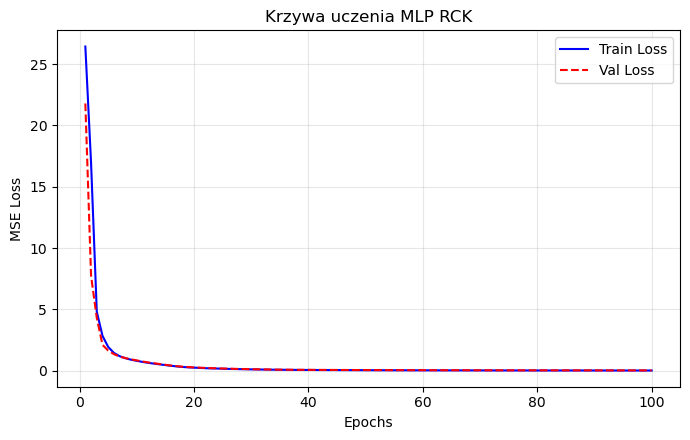

In [17]:
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, FINAL_EPOCHS + 1), train_losses, label='Train Loss', color='blue', linewidth=1.5)
plt.plot(range(1, FINAL_EPOCHS + 1), val_losses, label='Val Loss', color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Krzywa uczenia MLP RCK')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plot1_path = os.path.join(output_dir, "loss_history_MLP_RCK.png")
plt.savefig(plot1_path, dpi=300, bbox_inches='tight')
plt.show()

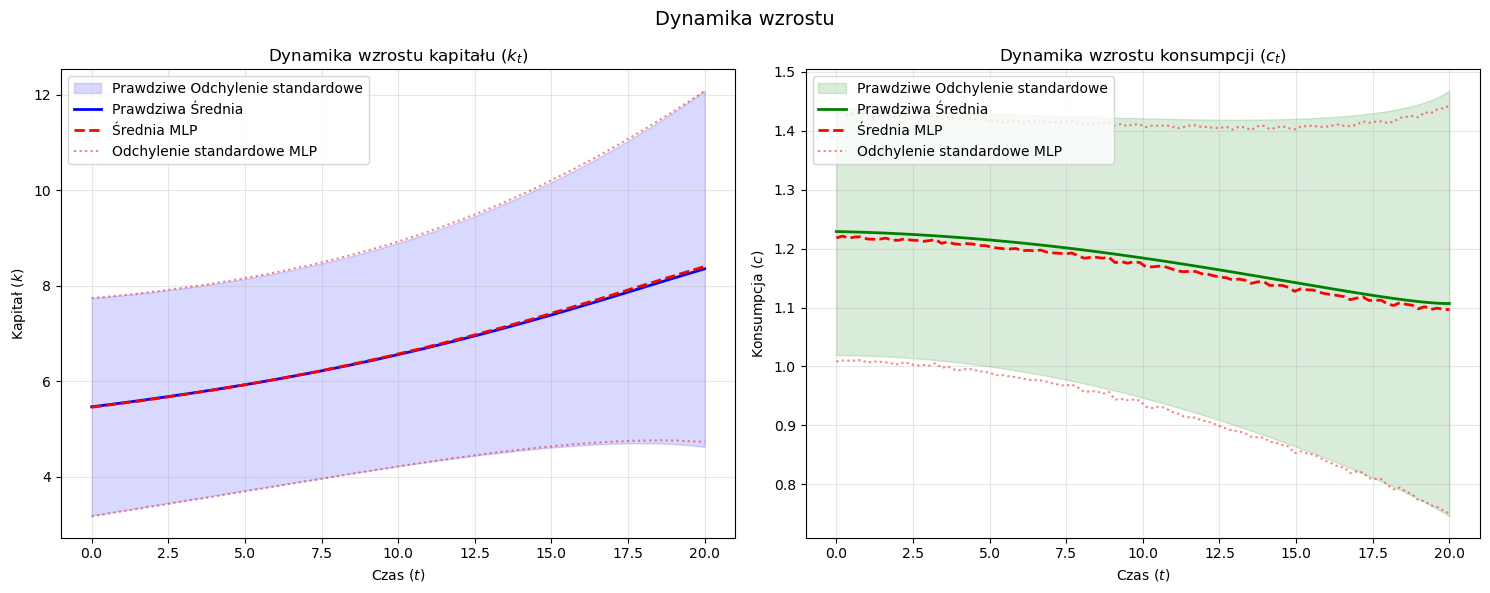

In [18]:
mean_target_k, mean_pred_k = targets_k.mean(axis=0), preds_k.mean(axis=0)
mean_target_c, mean_pred_c = targets_c.mean(axis=0), preds_c.mean(axis=0)
std_target_k, std_pred_k = targets_k.std(axis=0), preds_k.std(axis=0)
std_target_c, std_pred_c = targets_c.std(axis=0), preds_c.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].fill_between(time_axis, mean_target_k - std_target_k, mean_target_k + std_target_k, color='blue', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[0].plot(time_axis, mean_target_k, color='blue', linewidth=2, label='Prawdziwa Średnia')
axes[0].plot(time_axis, mean_pred_k, color='red', linestyle='--', linewidth=2, label='Średnia MLP')
axes[0].plot(time_axis, mean_pred_k + std_pred_k, color='red', linestyle=':', alpha=0.5)
axes[0].plot(time_axis, mean_pred_k - std_pred_k, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe MLP')
axes[0].set_title('Dynamika wzrostu kapitału ($k_t$)')
axes[0].set_xlabel('Czas ($t$)')
axes[0].set_ylabel('Kapitał ($k$)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

axes[1].fill_between(time_axis, mean_target_c - std_target_c, mean_target_c + std_target_c, color='green', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[1].plot(time_axis, mean_target_c, color='green', linewidth=2, label='Prawdziwa Średnia')
axes[1].plot(time_axis, mean_pred_c, color='red', linestyle='--', linewidth=2, label='Średnia MLP')
axes[1].plot(time_axis, mean_pred_c + std_pred_c, color='red', linestyle=':', alpha=0.5)
axes[1].plot(time_axis, mean_pred_c - std_pred_c, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe MLP')
axes[1].set_title('Dynamika wzrostu konsumpcji ($c_t$)')
axes[1].set_xlabel('Czas ($t$)')
axes[1].set_ylabel('Konsumpcja ($c$)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Dynamika wzrostu', fontsize=14, y=0.98)
plt.tight_layout()
plot2_path = os.path.join(output_dir, "RCK_MLP_growth_dynamics.png")
plt.savefig(plot2_path, dpi=300, bbox_inches='tight')
plt.show()

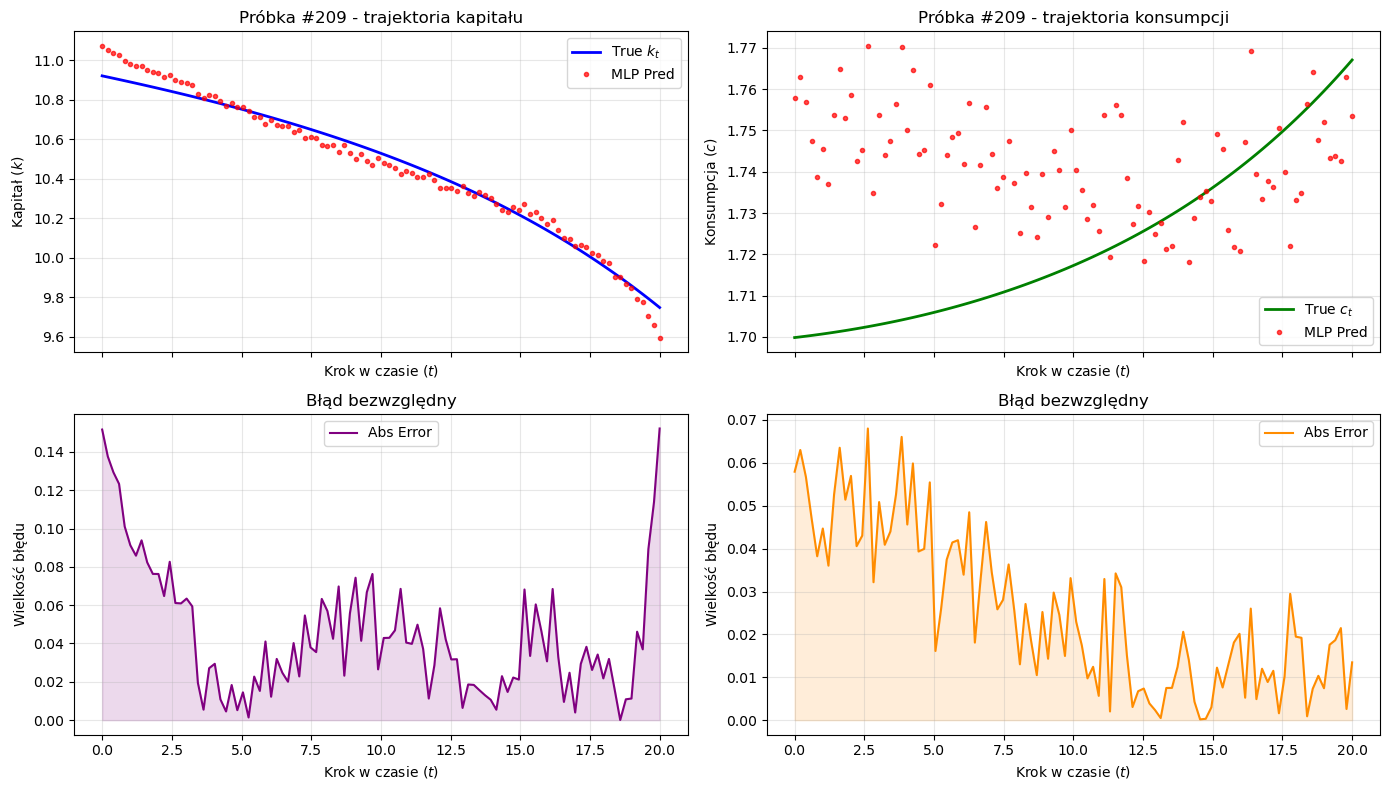

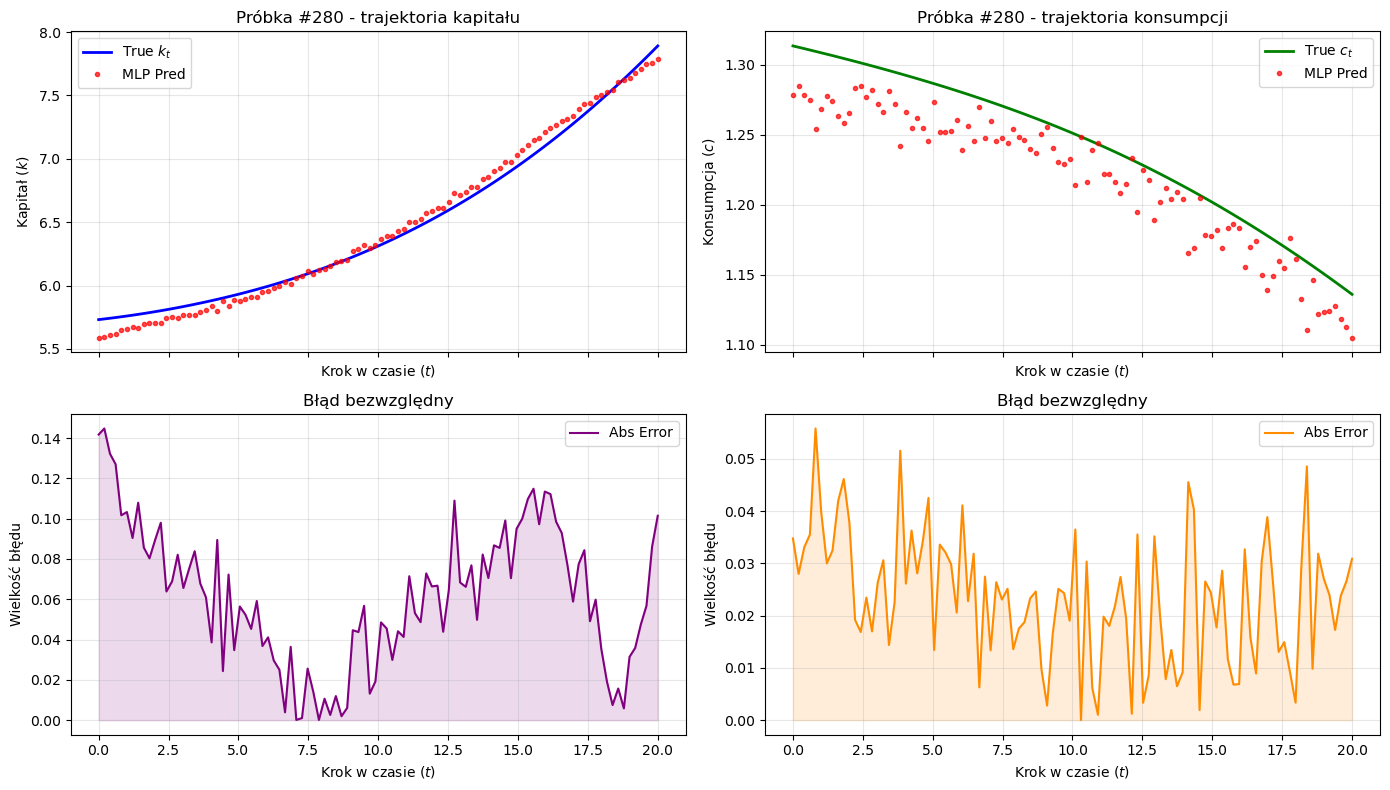

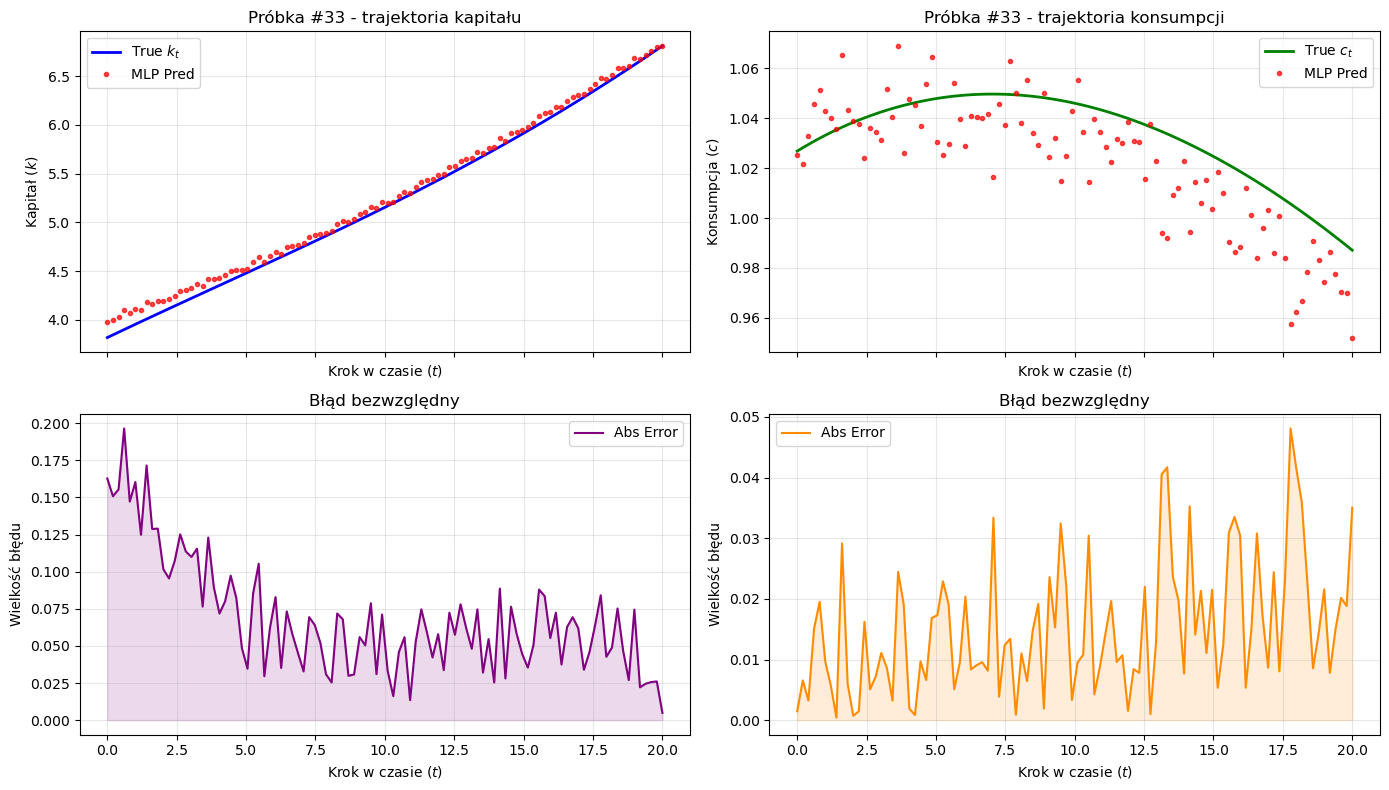

In [19]:
np.random.seed(42)
random_indices = np.random.choice(len(all_preds), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    axes[0, 0].plot(time_axis, targets_k[sample_idx], 'b-', linewidth=2, label='True $k_t$')
    axes[0, 0].plot(time_axis, preds_k[sample_idx], 'ro', markersize=3, alpha=0.7, label='MLP Pred')
    axes[0, 0].set_title(f'Próbka #{sample_idx} - trajektoria kapitału')
    axes[0, 0].set_ylabel('Kapitał ($k$)')
    axes[0, 0].set_xlabel('Krok w czasie ($t$)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    axes[1, 0].fill_between(time_axis, abs_error_k[sample_idx], color='purple', alpha=0.15)
    axes[1, 0].plot(time_axis, abs_error_k[sample_idx], color='purple', linewidth=1.5, label='Abs Error')
    axes[1, 0].set_title('Błąd bezwzględny')
    axes[1, 0].set_xlabel('Krok w czasie ($t$)')
    axes[1, 0].set_ylabel('Wielkość błędu')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    axes[0, 1].plot(time_axis, targets_c[sample_idx], 'g-', linewidth=2, label='True $c_t$')
    axes[0, 1].plot(time_axis, preds_c[sample_idx], 'ro', markersize=3, alpha=0.7, label='MLP Pred')
    axes[0, 1].set_title(f'Próbka #{sample_idx} - trajektoria konsumpcji')
    axes[0, 1].set_ylabel('Konsumpcja ($c$)')
    axes[0, 1].set_xlabel('Krok w czasie ($t$)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    axes[1, 1].fill_between(time_axis, abs_error_c[sample_idx], color='darkorange', alpha=0.15)
    axes[1, 1].plot(time_axis, abs_error_c[sample_idx], color='darkorange', linewidth=1.5, label='Abs Error')
    axes[1, 1].set_title('Błąd bezwzględny')
    axes[1, 1].set_xlabel('Krok w czasie ($t$)')
    axes[1, 1].set_ylabel('Wielkość błędu')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plot3_path = os.path.join(output_dir, f"3_sample_{sample_idx}_analysis_MLP_RCK.png")
    plt.savefig(plot3_path, dpi=300, bbox_inches='tight')
    plt.show()